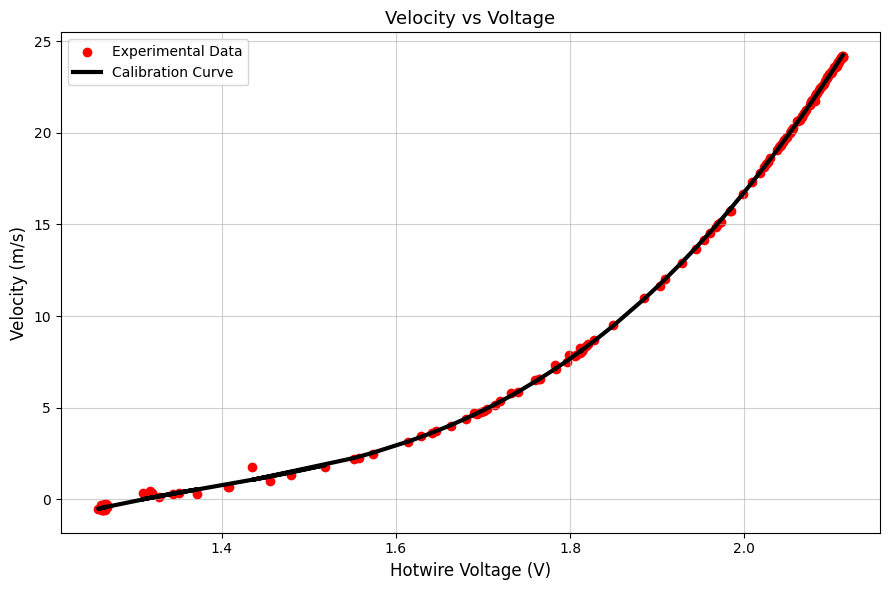

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('calibration.csv', skiprows=19)
vel = df["Pitot/static Probe Velocity [m/s]"]
#print(df)
volts = df[" Hotwire Ev [Volts]"]
a0 = -240.911
a1 = 556.286
a2 = -467.475
a3 = 164.528
a4 = -18.826
def func(x):
    return a0 + a1*x + a2*x**2 + a3*x**3+a4*x**4
cal = np.zeros_like(vel)
for i in range(volts.shape[0]):
    cal[i] = func(volts[i])
plt.figure(figsize=(9, 6))
plt.scatter(volts,vel,label = "Experimental Data",color = "red")
plt.plot(volts,cal, label = "Calibration Curve", color = "black", linewidth=3)
plt.xlabel("Hotwire Voltage (V)", fontsize=12)
plt.ylabel("Velocity (m/s)", fontsize=12)
plt.title(
    "Velocity vs Voltage",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.legend()

plt.show()

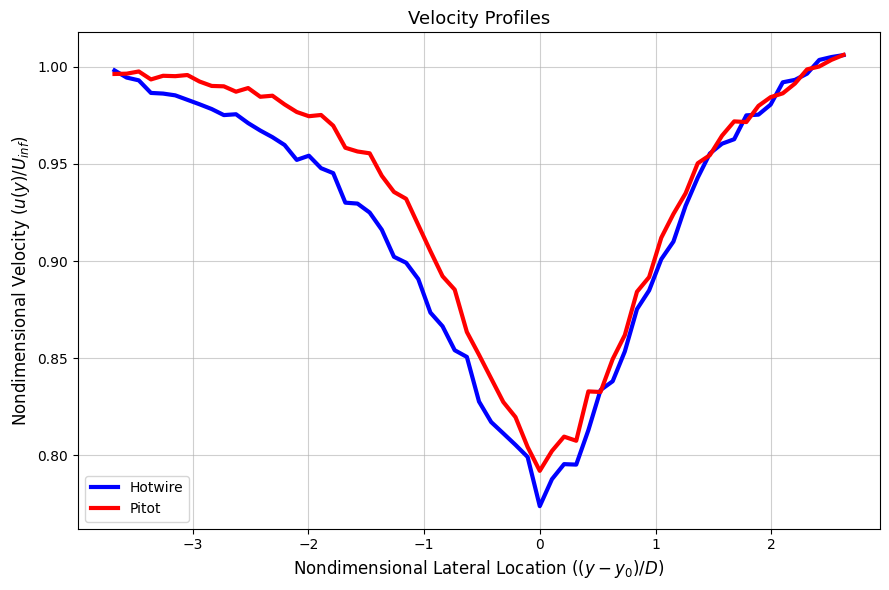

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
D = 19.05 #mm

df = pd.read_csv('velocityprofile.csv', skiprows=15)
y = df["Lateral Position [mm]"]
pitotvel = df[" Pitot/Static Vel [m/s]"]
hotwirevel = df[" Hot Wire Vel [m/s]"]
y0_pitot = y[pitotvel.idxmin()]
y0_hotwire = y[hotwirevel.idxmin()]

u_inf_pitot = pd.concat([pitotvel.iloc[:3], pitotvel.iloc[-3:]]).mean()
u_inf_hw = pd.concat([hotwirevel.iloc[:3], hotwirevel.iloc[-3:]]).mean()

y_hw_norm = hotwirevel/u_inf_hw
y_pitot_norm = pitotvel/u_inf_pitot

x_hw_norm = (y-y0_hotwire)/D
x_pitot_norm = (y-y0_pitot)/D
#print(y_hw_norm)
plt.figure(figsize=(9, 6))

plt.plot(x_hw_norm,y_hw_norm, label = "Hotwire", color = "blue", linewidth=3)
plt.plot(x_pitot_norm,y_pitot_norm, label = "Pitot", color = "red", linewidth=3)
plt.xlabel(r"Nondimensional Lateral Location ($(y - y_0)/D$)", fontsize=12)
plt.ylabel(r"Nondimensional Velocity ($u(y)/U_{inf}$)", fontsize=12)
plt.title(
    "Velocity Profiles",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.legend()

plt.show()


0.010875000000000001 0.009625 0.0205


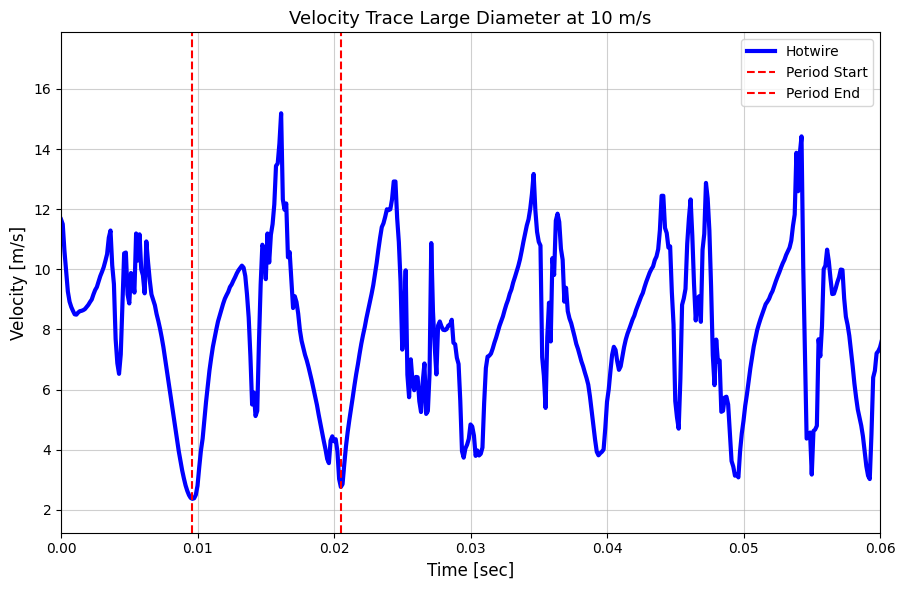

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


df = pd.read_csv("VelocityTrace10ms_largediameter.csv", skiprows=18)
time = df["Time [sec]"]
VelHW = df[" Velocity from Hotwire [m/s]"]

mask = (df["Time [sec]"] >= 0.008) & (df["Time [sec]"] <= 0.011)
window = df[mask]

min_idx = window[" Velocity from Hotwire [m/s]"].idxmin()

t_min = df.loc[min_idx, "Time [sec]"]
vel_min = df.loc[min_idx, " Velocity from Hotwire [m/s]"]

mask2 = (df["Time [sec]"] >= 0.019) & (df["Time [sec]"] <= 0.022)
window2 = df[mask2]

min_idx2 = window2[" Velocity from Hotwire [m/s]"].idxmin()

t_min2 = df.loc[min_idx2, "Time [sec]"]
vel_min2 = df.loc[min_idx2, " Velocity from Hotwire [m/s]"]

print(t_min2-t_min,t_min,t_min2)

plt.figure(figsize=(9, 6))

plt.plot(time,VelHW, label = "Hotwire", color = "blue", linewidth=3)
plt.axvline(t_min, color = "red",ls='--',label = "Period Start")
plt.axvline(t_min2, color = "red",ls='--',label = "Period End")
plt.xlabel("Time [sec]", fontsize=12)
plt.ylabel("Velocity [m/s]", fontsize=12)
plt.title(
    "Velocity Trace Large Diameter at 10 m/s",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.xlim(0, 0.06)
plt.legend()

plt.show()

Largest Time Period is the first period around $T_{start}=0.009625$ s and ends at $T_{end}=0.0205$ s. The total time then is around $T=0.010875$ s. The frequency is $1/T=91.95 \text{Hz}$

0.007375000000000001 0.00975 0.017125


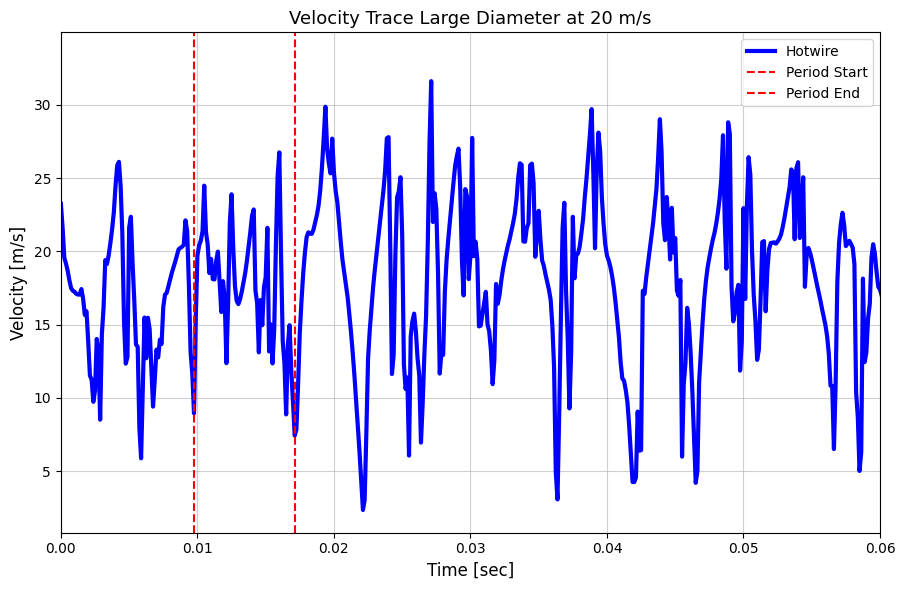

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


df = pd.read_csv("VelocityTrace20ms_largediameter.csv", skiprows=18)
time = df["Time [sec]"]
VelHW = df[" Velocity from Hotwire [m/s]"]

mask = (df["Time [sec]"] >= 0.008) & (df["Time [sec]"] <= 0.011)
window = df[mask]

min_idx = window[" Velocity from Hotwire [m/s]"].idxmin()

t_min = df.loc[min_idx, "Time [sec]"]
vel_min = df.loc[min_idx, " Velocity from Hotwire [m/s]"]

mask2 = (df["Time [sec]"] >= 0.015) & (df["Time [sec]"] <= 0.018)
window2 = df[mask2]

min_idx2 = window2[" Velocity from Hotwire [m/s]"].idxmin()

t_min2 = df.loc[min_idx2, "Time [sec]"]
vel_min2 = df.loc[min_idx2, " Velocity from Hotwire [m/s]"]

print(t_min2-t_min,t_min,t_min2)

plt.figure(figsize=(9, 6))

plt.plot(time,VelHW, label = "Hotwire", color = "blue", linewidth=3)
plt.axvline(t_min, color = "red",ls='--',label = "Period Start")
plt.axvline(t_min2, color = "red",ls='--',label = "Period End")
plt.xlabel("Time [sec]", fontsize=12)
plt.ylabel("Velocity [m/s]", fontsize=12)
plt.title(
    "Velocity Trace Large Diameter at 20 m/s",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.xlim(0, 0.06)
plt.legend()

plt.show()

0.00375 0.00625 0.01


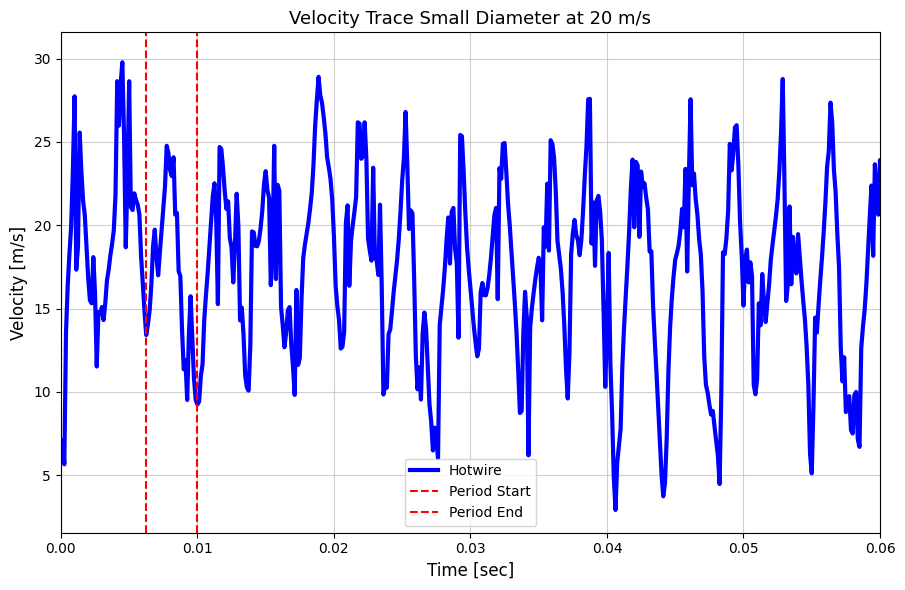

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


df = pd.read_csv("VelocityTrace20ms_smalldiameter.csv", skiprows=18)
time = df["Time [sec]"]
VelHW = df[" Velocity from Hotwire [m/s]"]

mask = (df["Time [sec]"] >= 0.006) & (df["Time [sec]"] <= 0.007)
window = df[mask]

min_idx = window[" Velocity from Hotwire [m/s]"].idxmin()

t_min = df.loc[min_idx, "Time [sec]"]
vel_min = df.loc[min_idx, " Velocity from Hotwire [m/s]"]

mask2 = (df["Time [sec]"] >= 0.009) & (df["Time [sec]"] <= 0.011)
window2 = df[mask2]

min_idx2 = window2[" Velocity from Hotwire [m/s]"].idxmin()

t_min2 = df.loc[min_idx2, "Time [sec]"]
vel_min2 = df.loc[min_idx2, " Velocity from Hotwire [m/s]"]

print(t_min2-t_min,t_min,t_min2)

plt.figure(figsize=(9, 6))

plt.plot(time,VelHW, label = "Hotwire", color = "blue", linewidth=3)
plt.axvline(t_min, color = "red",ls='--',label = "Period Start")
plt.axvline(t_min2, color = "red",ls='--',label = "Period End")
plt.xlabel("Time [sec]", fontsize=12)
plt.ylabel("Velocity [m/s]", fontsize=12)
plt.title(
    "Velocity Trace Small Diameter at 20 m/s",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.xlim(0, 0.06)
plt.legend()

plt.show()

0.009000000000000001 0.007125 0.016125


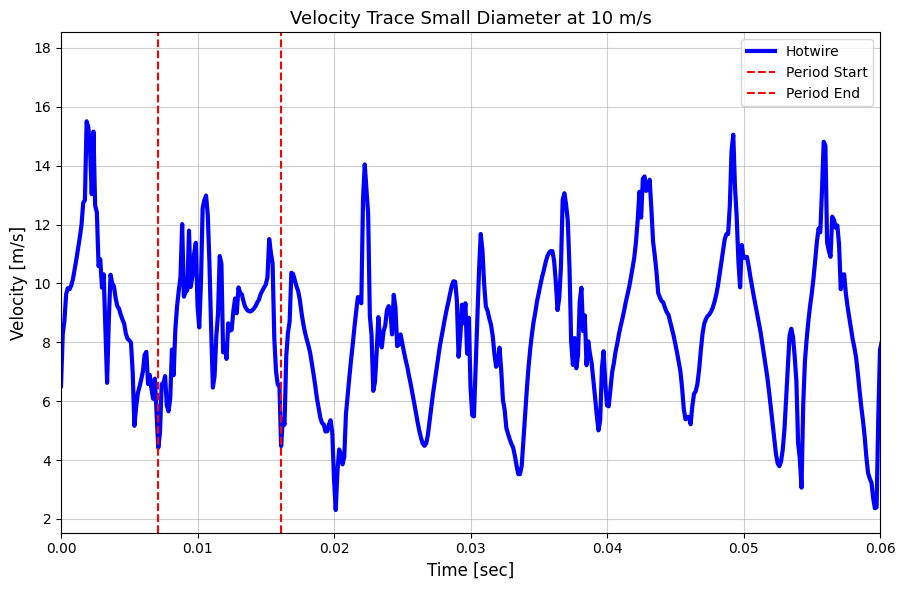

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


df = pd.read_csv("VelocityTrace10ms_smalldiameter.csv", skiprows=18)
time = df["Time [sec]"]
VelHW = df[" Velocity from Hotwire [m/s]"]

mask = (df["Time [sec]"] >= 0.006) & (df["Time [sec]"] <= 0.008)
window = df[mask]

min_idx = window[" Velocity from Hotwire [m/s]"].idxmin()

t_min = df.loc[min_idx, "Time [sec]"]
vel_min = df.loc[min_idx, " Velocity from Hotwire [m/s]"]

mask2 = (df["Time [sec]"] >= 0.015) & (df["Time [sec]"] <= 0.017)
window2 = df[mask2]

min_idx2 = window2[" Velocity from Hotwire [m/s]"].idxmin()

t_min2 = df.loc[min_idx2, "Time [sec]"]
vel_min2 = df.loc[min_idx2, " Velocity from Hotwire [m/s]"]

print(t_min2-t_min,t_min,t_min2)

plt.figure(figsize=(9, 6))

plt.plot(time,VelHW, label = "Hotwire", color = "blue", linewidth=3)
plt.axvline(t_min, color = "red",ls='--',label = "Period Start")
plt.axvline(t_min2, color = "red",ls='--',label = "Period End")
plt.xlabel("Time [sec]", fontsize=12)
plt.ylabel("Velocity [m/s]", fontsize=12)
plt.title(
    "Velocity Trace Small Diameter at 10 m/s",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.xlim(0, 0.06)
plt.legend()

plt.show()

In [8]:
import numpy as np
import pandas as pd

df = pd.read_csv("VelocityTrace10ms_largediameter.csv", skiprows=18)
time_col = df.columns[0]
vel_col = df.columns[1]


windows = [
    (0.008, 0.011),
    (0.019, 0.022),
    (0.028, 0.032),
    (0.038, 0.041),
    (0.048, 0.052),
    (0.058, 0.062),
]

t_valleys = []
vel_valleys = []

for t_low, t_high in windows:
    mask = (df[time_col] >= t_low) & (df[time_col] <= t_high)
    sub = df[mask]
    min_idx = sub[vel_col].idxmin()
    t_valleys.append(df.loc[min_idx, time_col])
    vel_valleys.append(df.loc[min_idx, vel_col])

# Calculate consecutive periods
delta_T = np.diff(t_valleys)
avg_delta_T = np.mean(delta_T)
freq_avg = 1.0 / avg_delta_T

for i, dt in enumerate(delta_T):
    print(f"Period {i+1} (V{i+1} -> V{i+2}): {dt:.6f} s ({dt*1000:.3f} ms)")

print(
    f"\nAverage Delta T (5 periods): {avg_delta_T:.6f} s ({avg_delta_T*1000:.3f} ms)"
)
print(f"Dominant Frequency: {freq_avg:.2f} Hz")



Period 1 (V1 -> V2): 0.010875 s (10.875 ms)
Period 2 (V2 -> V3): 0.009000 s (9.000 ms)
Period 3 (V3 -> V4): 0.009875 s (9.875 ms)
Period 4 (V4 -> V5): 0.010250 s (10.250 ms)
Period 5 (V5 -> V6): 0.009625 s (9.625 ms)

Average Delta T (5 periods): 0.009925 s (9.925 ms)
Dominant Frequency: 100.76 Hz


/s Large] Max: 1.6800 Vrms at 101.56 Hz
/s Small] Max: 1.6610 Vrms at 156.25 Hz
/s Large] Max: 2.9230 Vrms at 203.12 Hz
/s Small] Max: 2.9060 Vrms at 296.88 Hz


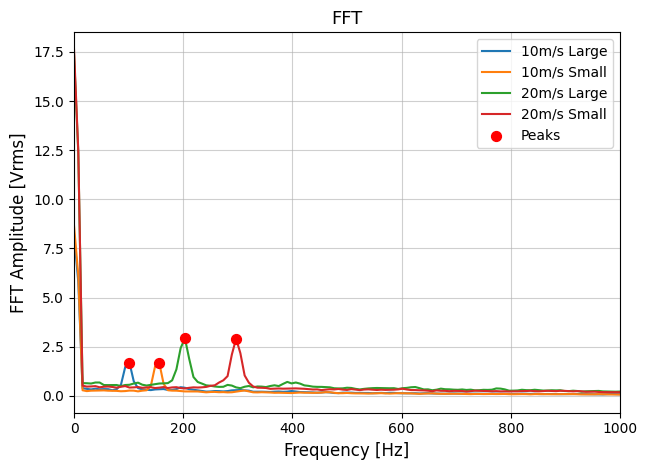

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df1 = pd.read_csv("FFT10ms_largediameter.csv",skiprows=17)
df2 = pd.read_csv("FFT10ms_smalldiameter.csv",skiprows=17)
df3 = pd.read_csv("FFT20ms_largediameter.csv",skiprows=17)
df4 = pd.read_csv("FFT20ms_smalldiameter.csv",skiprows=17)
freqx1 = df1["Frequency [Hz]"]
ampy1 = df1[" FFT Amplitude [Vrms]"]
freqx2 = df2["Frequency [Hz]"]
ampy2 = df2[" FFT Amplitude [Vrms]"]
freqx3 = df3["Frequency [Hz]"]
ampy3 = df3[" FFT Amplitude [Vrms]"]
freqx4 = df4["Frequency [Hz]"]
ampy4 = df4[" FFT Amplitude [Vrms]"]

dataframes = {
    "10m/s Large": df1,
    "10m/s Small": df2,
    "20m/s Large": df3,
    "20m/s Small": df4
}

maxfreqs = np.zeros(4)
maxamps = np.zeros(4)
count = 0
for label, df in dataframes.items():
    sliced_df = df.iloc[2:]
    
    idx_max = sliced_df[" FFT Amplitude [Vrms]"].idxmax()
    max_amp = sliced_df.loc[idx_max, " FFT Amplitude [Vrms]"]
    max_freq = sliced_df.loc[idx_max, "Frequency [Hz]"]
    
    print(f"[{label}] Max: {max_amp:.4f} Vrms at {max_freq:.2f} Hz")
    maxfreqs[count] = max_freq
    maxamps[count] = max_amp
    count += 1


plt.plot(freqx1,ampy1,label="10m/s Large")
plt.plot(freqx2,ampy2,label="10m/s Small")
plt.plot(freqx3,ampy3,label="20m/s Large")
plt.plot(freqx4,ampy4,label="20m/s Small")

plt.scatter(maxfreqs,maxamps, color='red', s=50, zorder=5, label="Peaks")
plt.ylabel("FFT Amplitude [Vrms]", fontsize=12)
plt.xlabel("Frequency [Hz]", fontsize=12)
plt.title(
    "FFT",
    fontsize=13,
)
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.xlim(0, 1000)
plt.legend()

plt.show()


In [61]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

L_L = 19.05 / 1000 #m
L_S = 12.70 / 1000 #m
U1 = 9.993 
U2 = 10.71
U3 = 20.265
U4 =  20.003
St1 = maxfreqs[0]*L_L/U1
St2 = maxfreqs[1]*L_S/U2
St3 = maxfreqs[2]*L_L/U3
St4 = maxfreqs[3]*L_S/U4
print(St1,St2,St3,St4)

0.1936111377964575 0.18528244631185806 0.19094652109548482 0.1884873518972154
